# Logistic Regression Model

CRISP-DM phase: Modelling + Evaluation

This notebook trains a logistic regression to predict whether a Kenyan county will have a recorded flood next month (`flood_next_month`), using the 24 features prepared in the preprocessing notebook plus `flood_this_month` (whether the county flooded this month).

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
import os
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_predict, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})

### 1.3 Features and Target

We predict at the end of month t whether a county floods in month t+1. `flood_this_month` says whether it flooded in month t, which is already known at that moment, so it is a lag of the target, like `rain_lag1`, and it is used as a feature (notebook 01, Section 4.3, checks that it is a clean lag). It also stays in `train` and `test` because it is the persistence baseline in Section 8. Two limits: it assumes this month's floods are known by the end of the month, and many floods last several months, so the model may partly "predict" floods that are already happening. Section 7 therefore scores new floods and continuing floods separately.

In [3]:
#columns that are not features: keys and target (flood_this_month stays a feature and is also the persistence baseline)
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month']

In [4]:
#separating the features (X) from the target (y)
X_train = train.drop(not_features, axis=1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis=1)
y_test = test['flood_next_month']

In [5]:
#shapes and number of floods in each set
print(X_train.shape, y_train.sum())
print(X_test.shape, y_test.sum())

(9870, 25) 882
(2820, 25) 144


In [6]:
#the list of features
print(X_train.columns.tolist())

['flood_this_month', 'rain_mm', 'rain_lag1', 'rain_lag2', 'rain_pct_normal', 'neighbour_rain', 'ndvi_pct_normal', 'oni', 'dmi', 'month_sin', 'month_cos', 'soil_moisture_l1', 'runoff_rank', 'discharge_rank', 'pct_flat', 'area_km2', 'lc_tree', 'lc_grass', 'lc_crop', 'lc_bare', 'pct_within_1km_river', 'pct_water', 'pct_occasional_water', 'pop_density', 'county_flood_rate']


In [7]:
#share of flood rows in each set
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

0.089 0.051


#### Observation

The training set has 9,870 rows with 882 floods (share 0.089) and the test set has 2,820 rows with 144 floods (share 0.051). Both have 25 features: the 24 features of the preprocessing notebook plus `flood_this_month`, which is the first column. The 4 keys and the target are not features. `flood_this_month` is still a column of `train` and `test`, so the persistence baseline can use it. The share of floods is also the PR-AUC of a model with no skill: 0.089 in training and 0.051 in the test set.

## 2. Cross-Validation and How the Settings Are Chosen

All the choices in this notebook (the settings of the model and the probability threshold) are made with 5-fold cross-validation on the training set only. The test set is used once, at the end, and nothing is changed after it.

The folds keep **whole years together** (`GroupKFold` with the year as the group). The counties in the same month share the same weather: `oni` and `dmi` have the same value for every county, and floods often hit many counties at once. If one county's October 2015 is in the training part and another county's October 2015 is in the validation part, the model can learn "October 2015 was a flood month" and the scores look better than they really are. With whole years held out, each fold is tested on years the model has not seen at all. The same folds are used in all the model notebooks.

In [8]:
#5-fold cross-validation that keeps whole years together
year_cv = GroupKFold(n_splits=5)

In [9]:
#years, rows and floods in the validation part of each fold
for fold, (train_idx, val_idx) in enumerate(year_cv.split(X_train, y_train, groups=train['year']), start=1):
    val_rows = train.iloc[val_idx]
    print('fold', fold, 'years', val_rows['year'].unique(), 'rows', len(val_rows), 'floods', val_rows['flood_next_month'].sum(), 'flood rate', round(val_rows['flood_next_month'].mean(), 3))

fold 1 years [2004 2009 2014 2019] rows 2256 floods 128 flood rate 0.057
fold 2 years [2003 2008 2013 2018] rows 2256 floods 175 flood rate 0.078
fold 3 years [2002 2007 2012 2017] rows 1974 floods 211 flood rate 0.107
fold 4 years [2006 2011 2016] rows 1692 floods 174 flood rate 0.103
fold 5 years [2005 2010 2015] rows 1692 floods 194 flood rate 0.115


#### Observation

Each fold holds out whole years: three or four years spread across the period (for example 2004, 2009, 2014 and 2019), so every fold has early, middle and late years. Folds 1 and 2 have 2,256 rows (four full years), folds 4 and 5 have 1,692 rows (three full years), and fold 3 has 1,974 rows because it holds 2002, which only has six months. Together the folds cover all 9,870 rows and all 882 floods once. The flood rate changes from 0.057 in fold 1 (128 floods) to 0.115 in fold 5 (194 floods). Because the folds are not balanced on floods, the scores are expected to change from fold to fold.

### 2.1 How the Settings Are Chosen

The work is done in two jobs.

**Job 1: choose the settings by PR-AUC.** PR-AUC (average precision) looks at all the possible probability cuts at once. It is high when the months that flood get higher probabilities than the months that do not, so it measures how well the model ranks the months. It does not go up just because a model warns more often. A model with no skill scores the share of floods (0.089 in the training set, see Section 1.3). `RandomizedSearchCV` tries 40 combinations of the settings, scores each one with PR-AUC in the 5 year folds and keeps the combination with the highest mean. All the settings are searched together, so a setting is judged together with the others and not alone, and the class weight is one of the settings searched. The values to try are given as plain lists, and `random_state=42` makes the search repeatable.

**Job 2: choose the threshold for 80% recall.** The model gives each month a flood probability, and the threshold decides from which probability on we raise a warning. Recall is still the main goal, because a missed flood is the most dangerous mistake: a county is not warned and lives can be lost. But recall is set by the threshold, not by weakening the model. We take the out-of-fold probabilities (each training row is predicted by a model that did not see its year) and pick the highest threshold where the out-of-fold recall is at least 0.80. The threshold comes from cross-validation only, never from the test set. Precision and the share of months flagged are shown next to recall, because false alarms waste money and staff time and make people stop trusting the warnings. We also checked the threshold with the highest F1 (Section 6.5). 80% recall was chosen because a missed flood is the most dangerous mistake.

**Limits that stay:** `GroupKFold` trains on years both before and after the held-out years, so it is not a pure forecast of the future, and `county_flood_rate` is calculated from all the training years, so the cross-validation scores are slightly optimistic.

## 3. Base Model

Logistic regression is first trained with all default settings. It is judged with the PR-AUC and the ROC-AUC of the year folds from Section 2. This is the starting point that the search in Section 4 has to beat. The features are not scaled yet.

In [10]:
#base model with all default settings
model_default = LogisticRegression()

In [11]:
#pr-auc and roc-auc in each fold for the default model
scores_default = cross_validate(model_default, X_train, y_train, cv=year_cv, groups=train['year'], scoring=['average_precision', 'roc_auc'])
print(scores_default['test_average_precision'].round(3))
print(scores_default['test_average_precision'].mean().round(3), scores_default['test_average_precision'].std().round(3))
print(scores_default['test_roc_auc'].mean().round(3), scores_default['test_roc_auc'].std().round(3))

c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessi

[0.059 0.127 0.126 0.221 0.116]
0.13 0.052
0.588 0.059


c:\Users\fadhi\anaconda3\envs\flood\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Observation

The default logistic regression has a mean PR-AUC of 0.13 (std 0.052) and a mean ROC-AUC of 0.588 (std 0.059) in the year folds. The PR-AUC is not far above 0.089, the score of a model with no skill (the flood share of the training set), and it changes a lot between folds (from 0.059 to 0.221). The warning `lbfgs failed to converge after 100 iteration(s)` shows that the model ran out of steps before it finished learning, so these scores are not trustworthy yet. Section 4 looks at why.

## 4. Iterations and Scaling

The default model printed a warning that it did not finish learning (`lbfgs failed to converge`). This section looks at that first, because it is a real lesson about this model. The warning is explained here, so it is hidden from this cell on.

In [12]:
#hiding the convergence warning from here on, it is explained in this section
warnings.filterwarnings('ignore', category=ConvergenceWarning)

In [13]:
#number of steps the model needed to finish learning
model_default.fit(X_train, y_train)
print(model_default.n_iter_)

[100]


#### Observation

The model used 100 steps, which is exactly the limit, so it stopped because it ran out of steps and not because it was finished.

In [14]:
#giving the model 1000 steps instead of 100
model_1000 = LogisticRegression(max_iter=1000)
model_1000.fit(X_train, y_train)
print(model_1000.n_iter_)

[1000]


#### Observation

Even with 1000 steps the model used all 1000 of them. More steps alone do not fix the problem, so the problem is not the number of steps.

In [15]:
#the features are on very different scales
X_train[['pop_density', 'area_km2', 'rain_mm', 'lc_tree', 'month_sin']].describe().round(2)

,pop_density,area_km2,rain_mm,lc_tree,month_sin
count,9870.00,9870.00,9870.00,9870.00,9870.00
mean,509.05,12407.92,91.53,0.25,-0.02
std,1162.55,17232.55,81.99,0.19,0.71
min,6.48,234.64,0.61,0.00,-1.00
25%,51.11,2529.99,25.75,0.08,-0.87
50%,220.63,3349.54,70.80,0.21,-0.00
75%,418.64,17207.16,135.62,0.40,0.50
max,6245.84,71424.71,676.70,0.69,1.00


#### Observation

The features are on very different scales: `area_km2` has a mean of 12407.92 and values up to 71424.71, `pop_density` has a mean of 509.05, `rain_mm` has a mean of 91.53, while `lc_tree` lies between 0.00 and 0.69 and `month_sin` between -1.00 and 1.00. The solver of logistic regression has a hard time when the features have such different sizes, which is why it does not finish.

In [16]:
#scaling the features first, then logistic regression with default settings
model_scaled = Pipeline([('scaler', StandardScaler()),
                         ('model', LogisticRegression())])
model_scaled.fit(X_train, y_train)
print(model_scaled.named_steps['model'].n_iter_)

[18]


In [17]:
#pr-auc and roc-auc in each fold for the scaled model
scores_scaled = cross_validate(model_scaled, X_train, y_train, cv=year_cv, groups=train['year'], scoring=['average_precision', 'roc_auc'])
print(scores_scaled['test_average_precision'].round(3))
print(scores_scaled['test_average_precision'].mean().round(3), scores_scaled['test_average_precision'].std().round(3))
print(scores_scaled['test_roc_auc'].mean().round(3), scores_scaled['test_roc_auc'].std().round(3))

[0.311 0.368 0.418 0.522 0.492]
0.422 0.078
0.803 0.031


#### Observation

After scaling, the model finished in 18 steps (the default limit is 100). Its mean PR-AUC in the year folds is 0.422 (std 0.078) against 0.13 before, and its mean ROC-AUC is 0.803 (std 0.031) against 0.588. So scaling matters a lot for logistic regression, and the unscaled scores in Section 3 were low because the model had not finished learning. The scaler is part of the pipeline in the search below, so in each fold it learns the mean and the standard deviation from the training part only.

## 5. Choosing the Settings with a Randomized Search

Scaling is part of the pipeline in this search, so in every fold the scaler learns the mean and the standard deviation from the training part only. The search uses the `liblinear` solver, which can use both the `l1` and the `l2` penalty, and `max_iter=2000` so that the model has enough steps to finish learning.

The settings searched are:

- `C`: how strongly the model is held back (regularisation). A small `C` holds it back a lot and a large `C` holds it back very little.
- `l1_ratio`: which penalty is used. 0 is the `l2` penalty, which shrinks all the coefficients a little. 1 is the `l1` penalty, which can set some of the coefficients to exactly zero. (Older versions of scikit-learn called this setting `penalty`, with the values `'l2'` and `'l1'`.)
- `class_weight`: `None` counts every row the same, `'balanced'` counts each flood more than a no-flood month, in proportion to how rare floods are.

The lists hold 10 values of `C`, 2 values of `l1_ratio` and 2 class weights, which is 40 combinations, so with `n_iter=40` the search tries every one of them.

In [18]:
#the values to try for each setting (model__ is the logistic regression step of the pipeline)
param_lists = {'model__C': [0.001, 0.003, 0.004, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
               'model__l1_ratio': [0, 1],
               'model__class_weight': [None, 'balanced']}

In [19]:
#the pipeline: scaling first, then logistic regression
pipe = Pipeline([('scaler', StandardScaler()),
                 ('model', LogisticRegression(solver='liblinear', max_iter=2000))])

In [20]:
#randomized search scored with pr-auc (average precision) on the year folds
search = RandomizedSearchCV(pipe, param_distributions=param_lists, n_iter=40, scoring='average_precision',
                            cv=year_cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train, groups=train['year'])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': [0.001, 0.003, ...], 'model__class_weight': [None, 'balanced'], 'model__l1_ratio': [0, 1]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` insta

In [21]:
#all the combinations tried, in the order of their mean pr-auc (None is written as the word None, because it would show as NaN)
results = pd.DataFrame(search.cv_results_).fillna('None')
top5 = results.sort_values('rank_test_score').head(5)
top5[['param_model__C', 'param_model__l1_ratio', 'param_model__class_weight', 'mean_test_score', 'std_test_score']].round(3)

,param_model__C,param_model__l1_ratio,param_model__class_weight,mean_test_score,std_test_score
8,0.004,0,None,0.439,0.068
4,0.003,0,None,0.439,0.068
12,0.010,0,None,0.439,0.069
0,0.001,0,None,0.433,0.069
13,0.010,1,None,0.433,0.052


In [22]:
#the best settings and their mean pr-auc in cross-validation
print(search.best_params_)
print(round(search.best_score_, 3), round(results.loc[search.best_index_, 'std_test_score'], 3))

{'model__l1_ratio': 0, 'model__class_weight': None, 'model__C': 0.004}
0.439 0.068


#### Observation

All 40 combinations were tried. The best settings are `C` = 0.004, the `l2` penalty (`l1_ratio` 0) and no class weight, with a mean PR-AUC of 0.439 (std 0.068 between the folds). That is above the 0.422 of the scaled model with default settings. The top 5 are very close: three settings have a mean of 0.439 (`C` of 0.004, 0.003 and 0.01 with `l2`), and the other two have 0.433. These gaps are much smaller than the std of 0.068 between the folds, so the settings in the top 5 are about equally good. All five use a small `C` (0.001 to 0.01), which means a strongly regularised model, and none uses the class weight. The class weight does not change how well the model ranks the months. Its role is taken by the threshold in Section 6.

In [23]:
#best model: the best settings fitted on the full training set by the search
best_model = search.best_estimator_

## 6. Choosing the Threshold for 80% Recall

The settings are fixed, so the next job is the threshold: the flood probability from which on we raise a warning. It is chosen with cross-validation only. The test set is not used here.

### 6.1 Out-of-Fold Probabilities

Each training row gets a flood probability from a model that was fitted on the other folds, so the model has not seen the years of that row.

In [24]:
#out-of-fold flood probabilities of the best model (every row is predicted by a model that did not see its year)
oof_prob = cross_val_predict(best_model, X_train, y_train, cv=year_cv, groups=train['year'], method='predict_proba')[:, 1]

In [25]:
#precision and recall for every possible threshold
precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)

### 6.2 The Threshold for 80% Recall

The recall gets lower when the threshold gets higher. We take the highest threshold where the out-of-fold recall is still at least 0.80, which gives the fewest warnings for that recall.

In [26]:
#choosing the threshold for 80% recall
threshold = thresholds[recall[:-1] >= 0.80].max()
print(threshold)

0.12454060107053355


In [27]:
#out-of-fold warnings at this threshold, and their recall, precision and share of months flagged
oof_pred = (oof_prob >= threshold).astype(int)
print('recall', round(recall_score(y_train, oof_pred), 3))
print('precision', round(precision_score(y_train, oof_pred), 3))
print('share of months flagged', round(oof_pred.mean(), 3))

recall 0.8
precision 0.166
share of months flagged 0.43


### 6.3 Confusion Matrix of the Out-of-Fold Predictions

The same kind of matrix as for the test set (Section 7.3), but for the training rows predicted out-of-fold at the chosen threshold. Each row is the true outcome and each column is the prediction.

In [28]:
#confusion matrix of the out-of-fold predictions at the chosen threshold, and the number of warnings
cm_oof = confusion_matrix(y_train, oof_pred)
print(cm_oof)
print('warnings', oof_pred.sum())

[[5451 3537]
 [ 176  706]]
warnings 4243


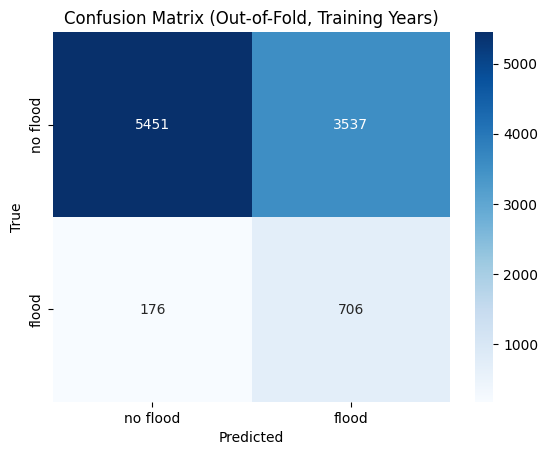

In [29]:
#heatmap of the out-of-fold confusion matrix
sns.heatmap(cm_oof, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Out-of-Fold, Training Years)')
plt.show()

#### Observation

In the out-of-fold predictions of the training years (882 floods), the logistic regression at the threshold of 0.125 finds 706 floods and misses 176. It gives 4,243 warnings, of which 3,537 are false alarms (a warning in a month with no flood). So there are far more false alarms than floods found, which agrees with the precision of 0.166 in Section 6.2. This is the price of a recall of 0.8: a lower threshold finds more floods and gives more false alarms, a higher one gives fewer false alarms and misses more floods (Section 6.4).

### 6.4 Other Recall Targets

The same steps for recall targets of 0.70 and 0.90, so the trade-off between recall and false alarms is visible.

In [30]:
#threshold, recall, precision and share of months flagged for three recall targets
targets = [0.70, 0.80, 0.90]
cut_list = []
recall_list = []
precision_list = []
flagged_list = []
for target in targets:
    cut = thresholds[recall[:-1] >= target].max()
    pred = (oof_prob >= cut).astype(int)
    cut_list.append(cut)
    recall_list.append(recall_score(y_train, pred))
    precision_list.append(precision_score(y_train, pred))
    flagged_list.append(pred.mean())
target_results = pd.DataFrame({'recall target': targets, 'threshold': cut_list, 'oof recall': recall_list,
                               'oof precision': precision_list, 'share of months flagged': flagged_list})
target_results.round(3)

,recall target,threshold,oof recall,oof precision,share of months flagged
0,0.7,0.142,0.701,0.193,0.324
1,0.8,0.125,0.800,0.166,0.430
2,0.9,0.105,0.900,0.138,0.583


### 6.5 The Threshold with the Highest F1 (for comparison)

F1 combines recall and precision. For comparison we also look for the threshold with the highest out-of-fold F1, next to the persistence baseline on the training rows (a flood this month means a flood next month).

In [31]:
#threshold with the highest out-of-fold f1
f1_values = pd.Series(2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1]))
best_f1_index = f1_values.idxmax()
print('threshold', round(thresholds[best_f1_index], 3))
print('recall', round(recall[best_f1_index], 3), 'precision', round(precision[best_f1_index], 3), 'f1', round(f1_values[best_f1_index], 3))
print('share of months flagged', round((oof_prob >= thresholds[best_f1_index]).mean(), 3))

threshold 0.362
recall 0.416 precision 0.511 f1 0.459
share of months flagged 0.073


In [32]:
#recall, precision and f1 of the persistence baseline on the training rows
print('recall', round(recall_score(y_train, train['flood_this_month']), 3))
print('precision', round(precision_score(y_train, train['flood_this_month']), 3))
print('f1', round(f1_score(y_train, train['flood_this_month']), 3))

recall 0.463
precision 0.463
f1 0.463


#### Observation

With a threshold of 0.125, the out-of-fold recall of the logistic regression is 0.8 (the target was 0.80), the precision is 0.166 and the model flags 0.43 of all the training months. The table shows the trade-off: for a recall of 0.70 the threshold is 0.142, the precision is 0.193 and 0.324 of the months are flagged; for a recall of 0.90 the threshold is 0.105, the precision is 0.138 and 0.583 of the months are flagged. Every extra bit of recall costs more false alarms.

The threshold with the highest F1 is 0.362. It gives a recall of only 0.416, a precision of 0.511 and an F1 of 0.459, and flags only 0.073 of the months. The persistence baseline on the training rows has a recall of 0.463, a precision of 0.463 and an F1 of 0.463. So at its best F1 threshold the logistic regression is about as good as the simple rule "a flood this month means a flood next month", and it does not catch more floods than that rule. This is why we set the threshold for 80% recall instead: recall is still the main goal, because a missed flood is the most dangerous mistake, and it is set by the threshold and not by weakening the model. The threshold comes from cross-validation only, and the test set was not used.

## 7. Evaluation on the Test Set

### 7.1 Predicting with the Chosen Threshold

The best settings of Section 4 were fitted on the whole training set (July 2002 to December 2019) by the search. The model is scored once on the test set (2020 to 2024), with the threshold of Section 6. A month gets a warning when its flood probability is at least the threshold. No setting is changed after this point.

In [33]:
#final model: the best settings, fitted on the full training set by the search
model = search.best_estimator_

In [34]:
#flood probabilities for the test set, and the warnings at the chosen threshold
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

### 7.2 Classification Report

In [35]:
#recall, precision and f1 for each class on the test set
print(classification_report(y_test, y_pred, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.99      0.67      0.80      2676
     1 flood       0.12      0.88      0.22       144

    accuracy                           0.68      2820
   macro avg       0.56      0.77      0.51      2820
weighted avg       0.95      0.68      0.77      2820



In [36]:
#recall, precision, f1, roc-auc and pr-auc of the test set
test_scores = pd.DataFrame({'recall': [recall_score(y_test, y_pred)],
                            'precision': [precision_score(y_test, y_pred)],
                            'f1': [f1_score(y_test, y_pred)],
                            'roc-auc': [roc_auc_score(y_test, y_prob)],
                            'pr-auc': [average_precision_score(y_test, y_prob)]})
test_scores.round(3)

,recall,precision,f1,roc-auc,pr-auc
0,0.875,0.125,0.219,0.87,0.388


#### Observation

On the test set, the logistic regression with the threshold of 0.125 has a recall of 0.875, a precision of 0.125 and an F1 of 0.219. The ROC-AUC is 0.87 and the PR-AUC is 0.388; a model with no skill would score 0.051 in PR-AUC (the share of floods in the test set). The classification report agrees: the flood class has a recall of 0.88 and a precision of 0.12, and the no-flood class has a recall of 0.67. The model gives 1,009 warnings in the 2,820 test months, so most warnings are false alarms.

The test recall is higher than the 0.80 of cross-validation. The threshold was fixed in Section 6 before the test set was used, so this is a result and not a target we tuned. Notebook 05 looks at the test years one by one to see where the difference comes from.

### 7.3 Confusion Matrix

Each row is the true outcome and each column is the prediction, so the numbers on the diagonal are correct predictions.

In [37]:
#confusion matrix of the test set at the chosen threshold, and the number of warnings
cm = confusion_matrix(y_test, y_pred)
print(cm)
print('warnings', y_pred.sum())

[[1793  883]
 [  18  126]]
warnings 1009


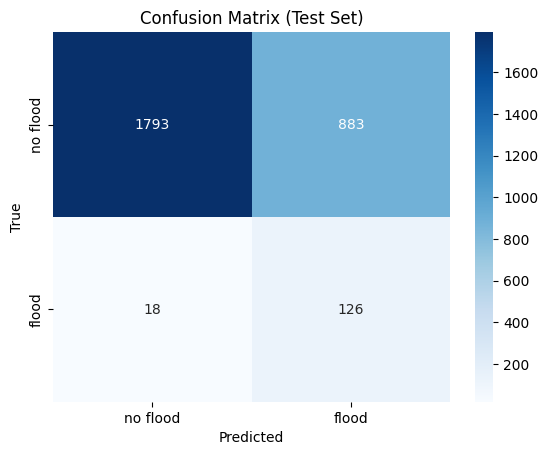

In [38]:
#heatmap of the test confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.show()

#### Observation

On the test set (144 floods), the logistic regression at the same threshold of 0.125 finds 126 floods and misses 18. It gives 1,009 warnings, of which 883 are false alarms. As in cross-validation there are far more false alarms than floods found (precision 0.125). The test recall (0.875) is higher than the out-of-fold recall (0.8), so a smaller share of the floods is missed. The threshold was not changed after the test set was used.

### 7.4 New Floods and Continuing Floods

A **new flood** is a flood next month in a county that did not flood this month (`flood_this_month` is 0). A **continuing flood** is a flood next month in a county that is already flooding this month (`flood_this_month` is 1). Continuing floods are easier to predict, so the two are scored separately.

In [39]:
#floods found among the new floods and among the continuing floods
new_floods = (y_test == 1) & (test['flood_this_month'] == 0)
continuing_floods = (y_test == 1) & (test['flood_this_month'] == 1)
print('new floods', new_floods.sum(), 'found', ((y_pred == 1) & new_floods).sum())
print('continuing floods', continuing_floods.sum(), 'found', ((y_pred == 1) & continuing_floods).sum())

new floods 76 found 58
continuing floods 68 found 68


In [40]:
#warnings in the months where the county is not flooding this month
print('warnings when the county is not flooding this month', ((y_pred == 1) & (test['flood_this_month'] == 0)).sum())
print('warnings when the county is flooding this month', ((y_pred == 1) & (test['flood_this_month'] == 1)).sum())

warnings when the county is not flooding this month 865
warnings when the county is flooding this month 144


#### Observation

Among the new floods (the county was not flooding this month), the logistic regression finds 58 of 76. Among the continuing floods (the county is already flooding this month), it finds 68 of 68. It gives 144 warnings in the months where the county is flooding this month (Section 8 shows that the persistence baseline warns 144 times, once for each of these months), so the continuing floods are found by this rule alone. The new floods are the real test, because the persistence baseline cannot find any of them. The model also gives 865 warnings in months where the county is not flooding this month, and these are where almost all the false alarms come from.

## 8. Comparison with Two Baselines

A model is only useful if it does better than simple rules that need no model. We compare it with two:

- **Persistence baseline:** predicts a flood next month whenever there is a flood this month (`flood_this_month`). It tests whether the model knows more than the current situation.
- **Calendar baseline:** gives every row the flood rate of its calendar month in the training years, so every March row gets the March rate, whatever the county or the rain. It tests whether the model knows more than the time of year. For a yes/no prediction it flags the months whose flood rate is above the overall training rate.

In [41]:
#persistence baseline predictions on the test set
base_pred = test['flood_this_month']

In [42]:
#flood rate of each calendar month in the training years
month_rate = train.groupby('month')['flood_next_month'].mean()
month_rate.round(3)

month
1     0.016
2     0.090
3     0.183
4     0.185
5     0.054
6     0.020
7     0.046
8     0.044
9     0.069
10    0.131
11    0.134
12    0.102
Name: flood_next_month, dtype: float64

In [43]:
#calendar baseline on the test set: the rate of the month, and yes/no when the rate is above the overall rate
calendar_prob = test['month'].map(month_rate)
calendar_pred = (calendar_prob > y_train.mean()).astype(int)

In [44]:
#months flagged by the calendar baseline and the number of test rows it flags
print(month_rate[month_rate > y_train.mean()].index.tolist())
print(calendar_pred.sum())

[2, 3, 4, 10, 11, 12]
1410


### 8.1 The Three Methods Side by Side

PR-AUC (average precision) does not depend on a probability cut, but it focuses on the flood class: a method with no skill scores the flood share of the test set (0.051). The number of different probabilities the model gives is checked first: rows with the same probability are tied in the rankings behind ROC-AUC and PR-AUC.

In [45]:
#number of different flood probabilities the model gives on the test set
pd.Series(y_prob).nunique()

2820

In [46]:
#recall, precision, f1, roc-auc, pr-auc and warnings for the two baselines and the model
comparison = pd.DataFrame({'method': ['Persistence baseline', 'Calendar baseline', 'Logistic regression'],
                           'recall': [recall_score(y_test, base_pred), recall_score(y_test, calendar_pred), recall_score(y_test, y_pred)],
                           'precision': [precision_score(y_test, base_pred), precision_score(y_test, calendar_pred), precision_score(y_test, y_pred)],
                           'f1': [f1_score(y_test, base_pred), f1_score(y_test, calendar_pred), f1_score(y_test, y_pred)],
                           'roc-auc': [roc_auc_score(y_test, base_pred), roc_auc_score(y_test, calendar_prob), roc_auc_score(y_test, y_prob)],
                           'pr-auc': [average_precision_score(y_test, base_pred), average_precision_score(y_test, calendar_prob), average_precision_score(y_test, y_prob)],
                           'warnings': [base_pred.sum(), calendar_pred.sum(), y_pred.sum()]})
comparison.round(3)

,method,recall,precision,f1,roc-auc,pr-auc,warnings
0,Persistence baseline,0.472,0.472,0.472,0.722,0.250,144
1,Calendar baseline,0.847,0.087,0.157,0.762,0.141,1410
2,Logistic regression,0.875,0.125,0.219,0.870,0.388,1009


#### Observation

The persistence baseline has a recall of 0.472 and also a precision of 0.472 with 144 warnings. The calendar baseline has a recall of 0.847 but a precision of 0.087 with 1410 warnings. The logistic regression has a recall of 0.875 and a precision of 0.125 with 1,009 warnings. It is better than both baselines in ROC-AUC (0.87 against 0.722 and 0.762) and in PR-AUC (0.388 against 0.250 and 0.141), and its recall is higher than both. But persistence has a higher precision (0.472) and a higher F1 (0.472 against 0.219), because it gives far fewer warnings. So the model buys its higher recall with many more warnings, and persistence alone is a strong rule. The ROC-AUC and PR-AUC of the two baselines are calculated from yes/no predictions and not from probabilities, so they are only a rough guide. The model gives 2820 different probabilities in the test set, so no rows are tied.

### 8.2 A Fair Recall Comparison

Recall depends on how many warnings a method raises: a method that flags more months will usually find more floods. To compare the model and the calendar baseline fairly, we let the model raise as many warnings as the calendar baseline, on the rows it thinks are most likely to flood. This is only a comparison, not a way of choosing the threshold. Rows with exactly the same probability cannot be told apart, so the number of floods found is given as a range.

In [47]:
#number of warnings raised by the calendar baseline and by the model
print(calendar_pred.sum())
print(y_pred.sum())

1410
1009


In [48]:
#ranking the test rows from the highest to the lowest flood probability
test_ranked = test.copy()
test_ranked['prob'] = y_prob
test_ranked = test_ranked.sort_values('prob', ascending=False)

In [49]:
#probability of the last warning if the model raised as many warnings as the calendar baseline
cut_prob = test_ranked['prob'].iloc[calendar_pred.sum() - 1]
print(cut_prob)

0.10566843361760599


In [50]:
#warnings and floods found with a probability above the cut, and with a probability above or equal to the cut
above = test_ranked[test_ranked['prob'] > cut_prob]
print(len(above), above['flood_next_month'].sum())
equal_or_above = test_ranked[test_ranked['prob'] >= cut_prob]
print(len(equal_or_above), equal_or_above['flood_next_month'].sum())

1409 138
1410 138


#### Observation

The calendar baseline gives 1410 warnings and the logistic regression gives 1,009. If the logistic regression gave as many warnings as the calendar baseline, with the cut at the probability 0.106, it would give 1409 warnings and 138 floods (probability above the cut) or 1410 warnings and 138 floods (above or equal to the cut), so one tied row does not change the number of floods found. It would find 138 of the 144 floods. The calendar baseline has a recall of 0.847 with its 1410 warnings (table in Section 8.1), so with the same number of warnings the logistic regression finds more floods than the calendar rule.

## 9. Looking Inside the Model

### 9.1 Coefficients

Because the features are scaled, the coefficients of the model can be compared with each other: a positive coefficient pushes the flood probability up and a negative one pushes it down. A coefficient of exactly 0 means the feature is not used.

In [51]:
#coefficients of the scaled features, from the largest to the smallest absolute value
coefficients = pd.DataFrame({'feature': X_train.columns, 'coefficient': model.named_steps['model'].coef_[0]})
coefficients['absolute'] = coefficients['coefficient'].abs()
coefficients = coefficients.sort_values('absolute', ascending=False)
coefficients.round(3)

,feature,coefficient,absolute
0,flood_this_month,0.490,0.490
2,rain_lag1,-0.221,0.221
24,county_flood_rate,0.213,0.213
5,neighbour_rain,0.163,0.163
8,dmi,0.139,0.139
1,rain_mm,0.096,0.096
10,month_cos,0.095,0.095
9,month_sin,0.084,0.084
13,discharge_rank,-0.079,0.079
3,rain_lag2,-0.079,0.079


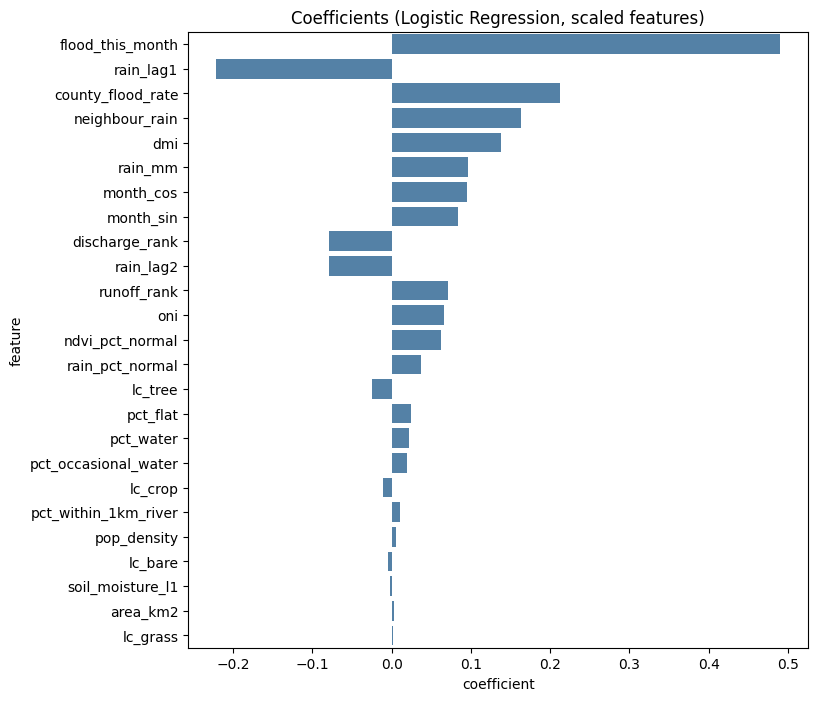

In [52]:
#bar chart of the coefficients
plt.figure(figsize=(8, 8))
sns.barplot(data=coefficients, x='coefficient', y='feature', color='steelblue')
plt.title('Coefficients (Logistic Regression, scaled features)')
plt.show()

#### Observation

The coefficient of `flood_this_month` is the largest (0.490): a county that floods this month has a higher flood probability next month. The next ones are `rain_lag1` (-0.221), `county_flood_rate` (0.213), `neighbour_rain` (0.163) and `dmi` (0.139). `rain_lag1` is negative while `rain_mm` is positive (0.096) and `rain_lag2` is negative (-0.079). The rain features are probably related to each other, so the sign of a single rain coefficient should not be read as "more rain lowers the risk". With the `l2` penalty no coefficient is set to exactly 0, but the area, soil moisture, population density, bare land and grass features have very small coefficients (0.006 or less in absolute value), so the model uses them very little.

## 10. Saving the Model

The final model is saved with `joblib` and its settings and threshold are saved in a `json` file, so that `05_model_comparison.ipynb` can load them instead of copying the settings by hand.

In [53]:
#creating the models folder if it does not exist yet
os.makedirs('../models', exist_ok=True)

In [54]:
#saving the final model
joblib.dump(model, '../models/logistic_regression.joblib', compress=3)

['../models/logistic_regression.joblib']

In [55]:
#best settings as plain python values so they can be saved in a json file
best_params = {}
for name, value in search.best_params_.items():
    if hasattr(value, 'item'):
        value = value.item()
    best_params[name] = value

In [56]:
#saving the settings, the threshold and the cross-validation scores
settings = {'model': 'Logistic regression',
            'best_params': best_params,
            'threshold': float(threshold),
            'recall_target': 0.80,
            'cv_pr_auc_mean': float(search.best_score_),
            'cv_pr_auc_std': float(results.loc[search.best_index_, 'std_test_score']),
            'oof_recall': float(recall_score(y_train, oof_pred)),
            'oof_precision': float(precision_score(y_train, oof_pred)),
            'share_flagged': float(oof_pred.mean())}
with open('../models/logistic_regression_settings.json', 'w') as settings_file:
    json.dump(settings, settings_file, indent=2)
print(settings)

{'model': 'Logistic regression', 'best_params': {'model__l1_ratio': 0, 'model__class_weight': None, 'model__C': 0.004}, 'threshold': 0.12454060107053355, 'recall_target': 0.8, 'cv_pr_auc_mean': 0.43940050513860285, 'cv_pr_auc_std': 0.06797501314868173, 'oof_recall': 0.800453514739229, 'oof_precision': 0.16639170398303088, 'share_flagged': 0.4298885511651469}


In [57]:
#files in the models folder
print(os.listdir('../models'))

['decision_tree.joblib', 'decision_tree_settings.json', 'logistic_regression.joblib', 'logistic_regression_settings.json', 'random_forest.joblib', 'random_forest_settings.json', 'xgboost.joblib', 'xgboost_settings.json']


## 11. Summary of the Logistic Regression Model

- **Method:** The features are scaled inside a pipeline, because the unscaled model did not finish learning (Section 4). Final settings: `StandardScaler` + `LogisticRegression(solver='liblinear', max_iter=2000)` with `C` = 0.004, the `l2` penalty and no class weight. The settings were chosen with `RandomizedSearchCV` scored with PR-AUC on 5 folds that keep whole years together (Job 1). The threshold was then chosen for 80% out-of-fold recall (Job 2), using cross-validation only.
- **Cross-validation:** mean PR-AUC 0.439 (std 0.068 between the folds).
- **Threshold:** 0.125. At this threshold the out-of-fold recall is 0.8, the precision is 0.166 and 0.43 of the months are flagged.
- **Test set (used once):** recall 0.875, precision 0.125, F1 0.219, ROC-AUC 0.87, PR-AUC 0.388, with 1,009 warnings in 2,820 months. New floods found: 58 of 76. Continuing floods found: 68 of 68.
- **Baselines:** the model has a higher recall, ROC-AUC and PR-AUC than the persistence and calendar baselines, but the persistence baseline has a higher precision and F1 because it warns only 144 times.
- **Scaling lesson:** without scaling the default model did not converge (100 of 100 steps used, and still 1000 of 1000 with more steps); after scaling it finished in 18 steps.
- **Saved:** the fitted model and its settings and threshold are saved in the `models` folder for `05_model_comparison.ipynb`.
- **Limits that stay:** (1) the folds hold out whole years but train on years before and after them, so cross-validation is not a pure forecast of the future; (2) `county_flood_rate` is calculated from all the training years, so the cross-validation scores are slightly optimistic; (3) the data stops in December 2024 (no 2025 data was added).
- **Feature selection:** the 24 features were chosen in the EDA notebooks using only the training rows (July 2002 to December 2019), so the test years were not used to choose them.

The next notebook, `DecisionTree.ipynb`, trains a decision tree in the same way.